# Jupyter Notebook Lab Evaluator
**Group 3 · Statistical NLP**

Grades a student's lab notebook (`.ipynb`) on its **code** and its **written explanation**, using simple NLP instead of an LLM.

For each student it gives: code correctness, expected output, errors, documentation quality, conceptual explanation, an overall mark out of 100 with a grade, and **one line saying where marks were lost**.

**Stretch goal:** it flags notebooks where *the code gives the correct output but the explanation describes a different algorithm* (e.g. the code uses a stemmer but the text talks about lemmatization).

**Input:** a lab's `rubric.json` (Section 2) and one or more student notebooks (Section 9). Works for any lab.

**Google Colab:** Runtime → Run all, then pick the rubric and notebooks when asked (Section 9).

### How one notebook is graded

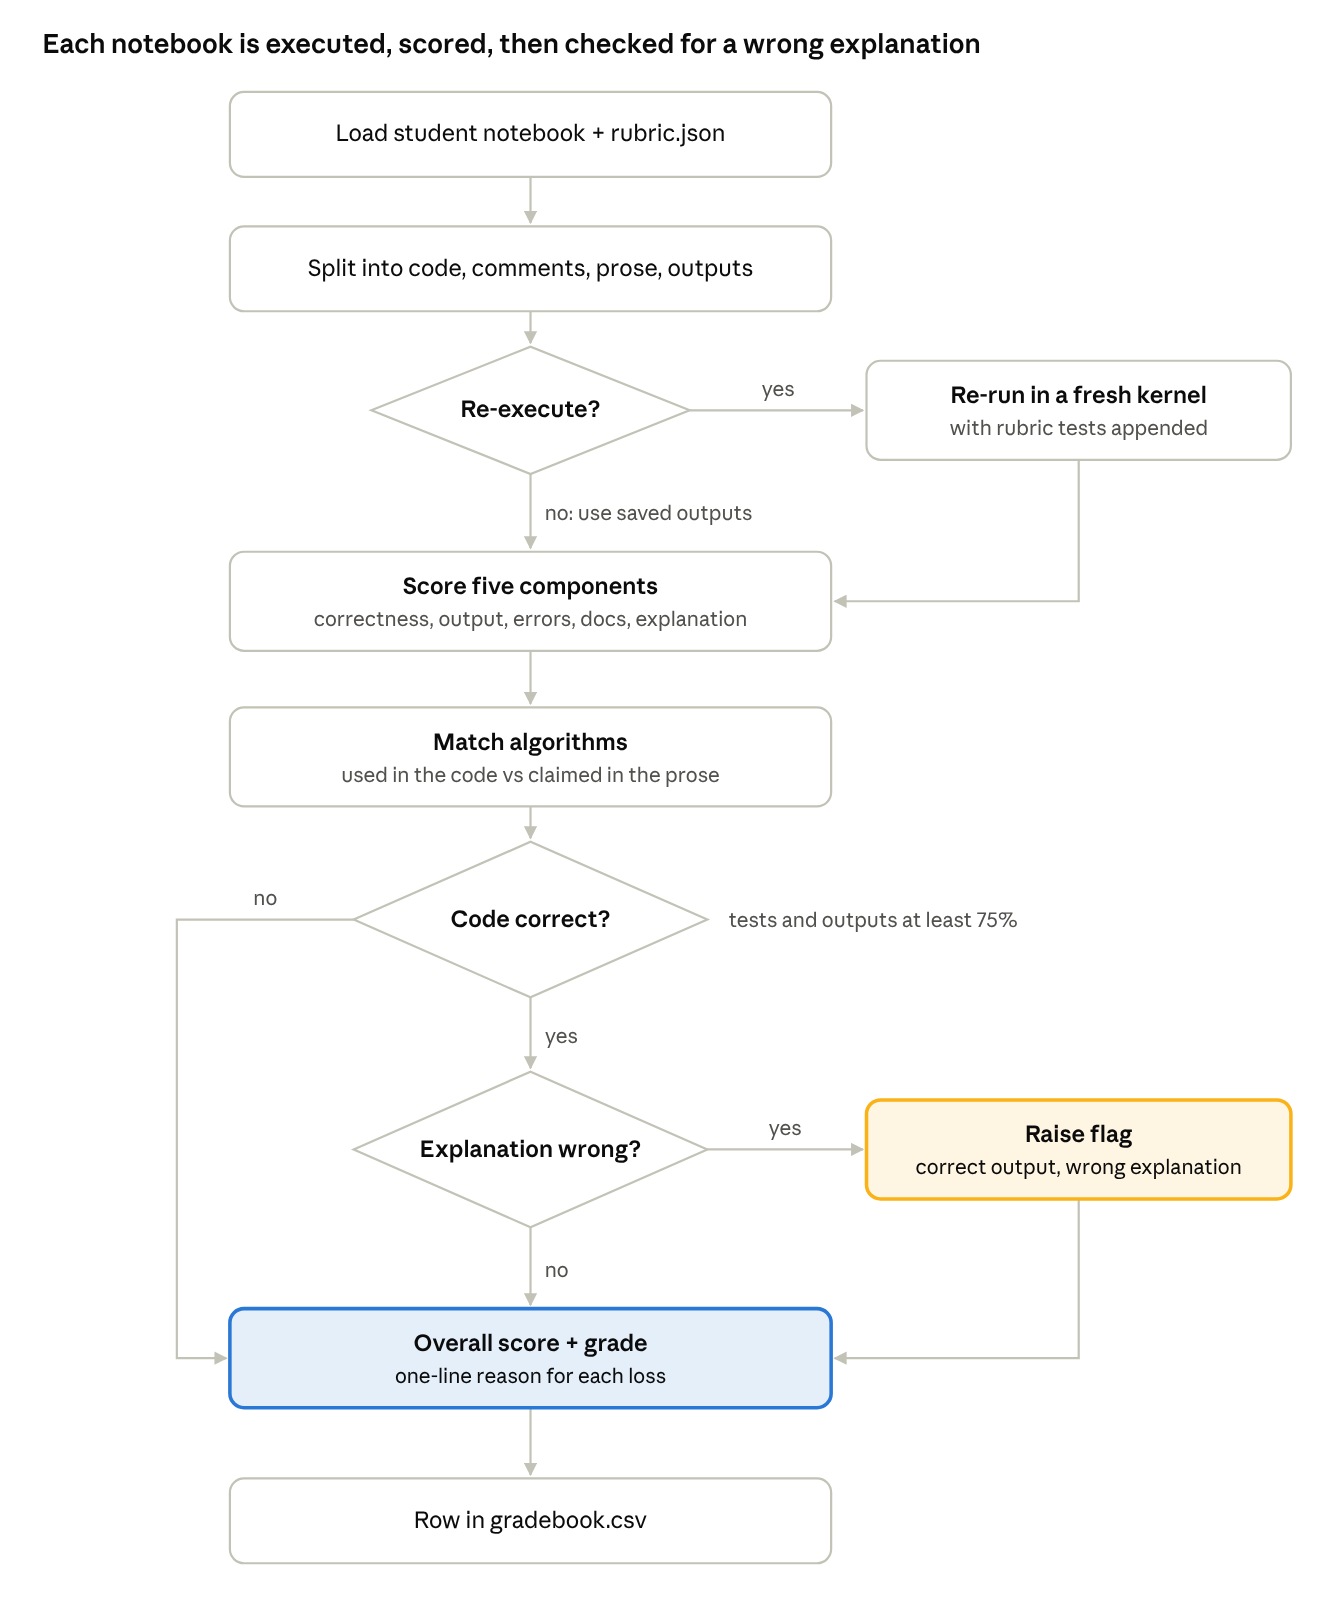

## 1. Setup

In [ ]:
import sys, subprocess, importlib.util
for module, package in [("nbformat", "nbformat"), ("nbclient", "nbclient"), ("ipykernel", "ipykernel"),
                        ("sklearn", "scikit-learn"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package])

import json, re, glob, tempfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, nbformat
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RUN_CODE = True        # re-run each student notebook and the rubric tests (set False to use saved outputs only)
WEIGHTS = {"correctness": 35, "output": 15, "errors": 15, "documentation": 15, "explanation": 20}   # marks out of 100
OUT = Path("reports"); OUT.mkdir(exist_ok=True)

# a kernel that uses this same Python, so student code sees the same packages
_ = subprocess.run([sys.executable, "-m", "ipykernel", "install", "--user", "--name", "lab-evaluator"], capture_output=True)

## 2. What a lab rubric looks like
One `rubric.json` per lab. Every part is optional.
```json
{
  "reference": "model answer explaining the algorithm",
  "concepts":  {"stemming": ["stem", "porter"], "tf-idf": ["tf-idf", "inverse document frequency"]},
  "expected":  [{"name": "accuracy >= 0.8", "pattern": "accuracy\\D*([0-9.]+)", "min": 0.8}],
  "tests":     {"model is Naive Bayes": "assert type(model).__name__ == 'MultinomialNB'"}
}
```
* `concepts`: ideas the explanation should mention, each with words that count as mentioning it.
* `expected`: results the printed output should contain (`contains` text, or a number captured by `pattern` within `min`/`max`).
* `tests`: Python checks run after the student's notebook, so they can look at the student's variables.

## 3. Read a notebook (code / text separation)

In [ ]:
def read_notebook(nb):
    if not isinstance(nb, nbformat.NotebookNode):
        nb = nbformat.read(nb, as_version=4)
    code, comments, text, outputs, errors, not_run = [], [], [], [], [], 0
    for cell in nb.cells:
        if cell.metadata.get("test"):
            continue
        if cell.cell_type == "markdown":
            text.append(re.sub(r"^# .*$", "", cell.source, flags=re.M))
        elif cell.cell_type == "code":
            for line in cell.source.splitlines():
                code.append(line.split("#")[0])
                if "#" in line:
                    comments.append(line.split("#", 1)[1].strip())
            if cell.get("execution_count") is None:
                not_run += 1
            for o in cell.get("outputs", []):
                if o.output_type == "error":
                    errors.append(f"{o.ename}: {o.evalue}")
                else:
                    outputs.append(o.get("text") or o.get("data", {}).get("text/plain", ""))
    return {"code": "\n".join(code), "comments": comments, "text": " ".join(text),
            "outputs": "\n".join(outputs), "errors": errors, "not_run": not_run,
            "code_cells": sum(c.cell_type == "code" for c in nb.cells),
            "functions": re.findall(r"def (\w+)\(.*\):\s*\n\s*(\"\"\"|''')?", "\n".join(c.source for c in nb.cells if c.cell_type == "code"))}


## 4. Run the notebook and the rubric tests
The student notebook runs in a fresh kernel in a separate process, with the rubric tests added at the end.

In [ ]:
RUNNER = """
import sys, nbformat
from nbclient import NotebookClient
nb = nbformat.read(sys.argv[1], as_version=4)
NotebookClient(nb, timeout=60, allow_errors=True, kernel_name="lab-evaluator",
               resources={"metadata": {"path": sys.argv[3]}}).execute()
nbformat.write(nb, sys.argv[2])
"""


def run_notebook(path, tests):
    nb = nbformat.read(path, as_version=4)
    for name, test in tests.items():
        body = "\n".join("    " + l for l in test.splitlines())
        cell = nbformat.v4.new_code_cell(f"try:\n{body}\n    print('PASS', {name!r})\nexcept Exception:\n    print('FAIL', {name!r})")
        cell.metadata["test"] = True
        nb.cells.append(cell)
    with tempfile.TemporaryDirectory() as tmp:
        src, dst = f"{tmp}/in.ipynb", f"{tmp}/out.ipynb"
        nbformat.write(nb, src)
        subprocess.run([sys.executable, "-c", RUNNER, src, dst, str(Path(path).parent.resolve())], capture_output=True, timeout=600)
        nb = nbformat.read(dst, as_version=4)
    test_output = "".join(o.get("text", "") for c in nb.cells if c.metadata.get("test") for o in c.outputs)
    passed = [name for name in tests if f"PASS {name}" in test_output]
    return nb, passed


## 5. Algorithms the evaluator knows
For each algorithm: its family, words that show it is **used in the code**, and words that show it is **described in the text**. Two algorithms in the same family are alternatives (you stem *or* lemmatize), which is how a wrong explanation is spotted. Add a line here to support a new lab.

In [ ]:
ALGORITHMS = {
    "stemming": ("normalisation", ["stemmer"], ["stem", "porter"]),
    "lemmatization": ("normalisation", ["lemmatiz"], ["lemmatiz", "lemma"]),
    "TF-IDF": ("features", ["tfidf"], ["tf-idf", "tfidf", "inverse document frequency"]),
    "bag of words": ("features", ["countvectorizer"], ["bag of words", "bag-of-words", "raw count"]),
    "word embeddings": ("features", ["word2vec", "sentencetransformer"], ["embedding", "word2vec"]),
    "Naive Bayes": ("classifier", ["naive_bayes", "nb("], ["naive bayes"]),
    "logistic regression": ("classifier", ["logisticregression"], ["logistic regression", "sigmoid"]),
    "SVM": ("classifier", ["svc("], ["support vector", "svm"]),
    "k-nearest neighbours": ("classifier", ["kneighbors"], ["nearest neighbo", "knn"]),
    "decision tree": ("classifier", ["decisiontree"], ["decision tree"]),
    "random forest": ("classifier", ["randomforest"], ["random forest"]),
    "K-Means": ("clustering", ["kmeans"], ["k-means", "kmeans"]),
    "hierarchical clustering": ("clustering", ["agglomerative", "linkage("], ["hierarchical", "agglomerative", "dendrogram"]),
    "DBSCAN": ("clustering", ["dbscan"], ["dbscan"]),
    "PCA": ("reduction", ["pca("], ["principal component", "pca"]),
}


def algorithms_in_code(code):
    code = code.lower()
    return {a for a, (_, words, _) in ALGORITHMS.items() if any(w in code for w in words)}


def algorithms_in_text(text):
    text = text.lower()
    return {a for a, (_, _, words) in ALGORITHMS.items() if any(re.search(r"\b" + re.escape(w), text) for w in words)}


def wrong_algorithms(code_algos, text_algos):
    return [(t, c) for t in text_algos - code_algos for c in code_algos if ALGORITHMS[t][0] == ALGORITHMS[c][0]]


## 6. Semantic similarity
Compares the student's explanation with the model answer. Uses a sentence-transformer model if it can be loaded (it usually can in Colab), otherwise TF-IDF cosine similarity.

In [ ]:
try:
    from sentence_transformers import SentenceTransformer
    sbert = SentenceTransformer("all-MiniLM-L6-v2")
except Exception:
    sbert = None
print("Similarity model:", "sentence-transformers" if sbert else "TF-IDF")

def similarity(a, b):
    if not a.strip() or not b.strip():
        return 0.0
    if sbert:
        x, y = sbert.encode([a, b], normalize_embeddings=True)
        return float(np.clip((x @ y - 0.2) / 0.5, 0, 1))      # rescale so 0.7 and above counts as a full match
    m = TfidfVectorizer(stop_words="english").fit_transform([a, b])
    return float(min(1, cosine_similarity(m[0], m[1])[0, 0] / 0.5))

## 7. Scoring
Each check returns a score from 0 to 1 and a one-line reason when marks are lost.

In [ ]:
def check_correctness(nb, passed, tests):
    if tests:
        failed = len(tests) - len(passed)
        return len(passed) / len(tests), f"{failed} of {len(tests)} tests failed" if failed else ""
    return max(0, 1 - len(nb["errors"]) / max(1, nb["code_cells"])), "some cells failed" if nb["errors"] else ""


def check_output(nb, expected):
    if not expected:
        return None, ""
    missing = 0
    for e in expected:
        if "contains" in e:
            ok = e["contains"].lower() in nb["outputs"].lower()
        else:
            numbers = [float(x) for x in re.findall(e["pattern"], nb["outputs"], re.I)]
            ok = any(e.get("min", -1e9) <= x <= e.get("max", 1e9) for x in numbers)
        missing += not ok
    return 1 - missing / len(expected), f"{missing} expected result(s) missing" if missing else ""


def check_errors(nb):
    score = max(0, 1 - 0.3 * len(nb["errors"]) - 0.1 * nb["not_run"])
    problems = ([f"{len(nb['errors'])} runtime error(s)"] if nb["errors"] else []) + (["cells not run"] if nb["not_run"] else [])
    return score, ", ".join(problems)


def check_documentation(nb):
    words = len(nb["text"].split())
    code_lines = max(1, sum(1 for l in nb["code"].splitlines() if l.strip()))
    with_doc = sum(1 for _, doc in nb["functions"] if doc)
    checks = {"too little written explanation": min(1, words / 150),
              "too few comments": min(1, len(nb["comments"]) / code_lines / 0.15),
              "functions lack docstrings": with_doc / len(nb["functions"]) if nb["functions"] else 1}
    return np.mean(list(checks.values())), ", ".join(k for k, v in checks.items() if v < 0.8)


def check_explanation(nb, rubric, wrong):
    text = nb["text"].lower()
    concepts = rubric.get("concepts", {})
    covered = [c for c, words in concepts.items() if any(w in text for w in words)]
    coverage = len(covered) / len(concepts) if concepts else 1
    score = 0.6 * coverage + 0.4 * similarity(nb["text"], rubric.get("reference", nb["code"]))
    if len(text.split()) < 30:
        return score * 0.5, "explanation too short"
    if wrong:
        return score * 0.2, "describes a different algorithm than the code"
    return score, "key concepts missing" if coverage < 1 else ("only partly matches the model answer" if score < 0.9 else "")


## 8. Evaluate one notebook

In [ ]:
def grade(mark):
    return "A" if mark >= 90 else "B" if mark >= 80 else "C" if mark >= 70 else "D" if mark >= 60 else "F"


def evaluate(path, rubric={}):
    tests = rubric.get("tests", {})
    raw, passed = run_notebook(path, tests) if RUN_CODE else (nbformat.read(path, as_version=4), [])
    nb = read_notebook(raw)
    nb["not_run"] = read_notebook(path)["not_run"]
    code_algos, text_algos = algorithms_in_code(nb["code"]), algorithms_in_text(nb["text"])
    wrong = wrong_algorithms(code_algos, text_algos)
    results = {"correctness": check_correctness(nb, passed, tests if RUN_CODE else {}),
               "output": check_output(nb, rubric.get("expected")),
               "errors": check_errors(nb),
               "documentation": check_documentation(nb),
               "explanation": check_explanation(nb, rubric, wrong)}
    used = {k: w for k, w in WEIGHTS.items() if results[k][0] is not None}
    scale = 100 / sum(used.values())
    row = {"student": Path(path).stem}
    lost = []
    for k, w in used.items():
        score, reason = results[k]
        marks, out_of = score * w * scale, w * scale
        row[f"{k} (/{out_of:.0f})"] = round(marks, 1)
        if out_of - marks >= 0.5 and reason:
            lost.append(f"{k} -{out_of - marks:.1f}: {reason}")
    row["total (/100)"] = round(sum(v for k, v in row.items() if "(/" in k), 1)
    row["grade"] = grade(row["total (/100)"])
    row["marks lost"] = "; ".join(lost) or "none"
    output_ok = results["output"][0] is None or results["output"][0] >= 0.75
    code_correct = results["correctness"][0] >= 0.75 and output_ok
    row["correct output, wrong explanation"] = ", ".join(f"says {t}, code uses {c}" for t, c in wrong) if code_correct and wrong else ""
    return row


## 9. Input: rubric and student notebooks
* **Colab:** run this cell and pick the `rubric.json` and the student `.ipynb` files from your computer.
* **Local / Google Drive:** point `RUBRIC` and `NOTEBOOKS` at your files (`NOTEBOOKS` can use `*`).

In [ ]:
UPLOAD = "google.colab" in sys.modules
RUBRIC = "samples/real/text_classification/rubric.json"
NOTEBOOKS = "samples/real/text_classification/*.ipynb"
# other labs: samples/real/kmeans, samples/synthetic/spam_detection, samples/synthetic/customer_segments, samples/synthetic/news_topics

if UPLOAD:
    from google.colab import files
    Path("uploads").mkdir(exist_ok=True)
    for name, data in files.upload().items():
        (Path("uploads") / name).write_bytes(data)
    RUBRIC, NOTEBOOKS = next(Path("uploads").glob("*.json"), None), "uploads/*.ipynb"

rubric = json.loads(Path(RUBRIC).read_text()) if RUBRIC else {}
notebooks = sorted(Path(p) for p in glob.glob(str(NOTEBOOKS)))
print(f"Rubric: {RUBRIC}\nNotebooks: {[p.name for p in notebooks]}")

## 10. Grade
Writes `reports/gradebook.csv` for teachers and `reports/results.json` for other programs (one record per student with a confidence score).

In [ ]:
pd.set_option("display.max_colwidth", 200)
gradebook = pd.DataFrame([evaluate(p, rubric) for p in notebooks]).set_index("student")
gradebook.to_csv(OUT / "gradebook.csv")
gradebook

In [ ]:
def confidence(row):
    """Rough 0-1 confidence in a mark: lower when the evidence is weak or a teacher should look."""
    c = 1.0
    if sbert is None:
        c -= 0.1                                   # TF-IDF similarity is cruder
    if not (RUN_CODE and rubric.get("tests")):
        c -= 0.2                                   # no tests, so correctness is a guess
    if row["correct output, wrong explanation"]:
        c -= 0.2                                   # flagged notebooks need a human check
    if min(abs(row["total (/100)"] - b) for b in (60, 70, 80, 90)) < 2:
        c -= 0.1                                   # close to a grade boundary
    return round(c, 2)

def to_json(row):
    marks = {k.split(" (")[0]: v for k, v in row.items() if "(/" in k and not k.startswith("total")}
    return {"input_id": row["student"],
            "result": {"marks": marks, "total": row["total (/100)"], "grade": row["grade"],
                       "marks_lost": row["marks lost"], "wrong_explanation": row["correct output, wrong explanation"],
                       "confidence": confidence(row)}}

results = [to_json(r) for r in gradebook.reset_index().to_dict("records")]
(OUT / "results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results[0], indent=2))

## 11. Mark and grade distribution

In [ ]:
print(gradebook["total (/100)"].describe().round(1).to_string())
print("\nStudents per grade:", gradebook["grade"].value_counts().reindex(list("ABCDF"), fill_value=0).to_dict())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(gradebook["total (/100)"], bins=range(0, 101, 10), color="#3B6FD4", rwidth=0.9)
ax.set(xlabel="Total mark (out of 100)", ylabel="Students", title="Mark distribution")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(OUT / "mark_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. How well does the evaluator work?
**Baseline vs improved:** the baseline scores an explanation only by rubric keywords; the improved version adds semantic similarity and the algorithm check.

**Agreement with teachers:** add `human_scores.csv` (columns `student,human_score`) to get MAE, RMSE and correlation.

In [ ]:
concepts = rubric.get("concepts", {})
rows = []
for p in notebooks:
    text = read_notebook(p)["text"].lower()
    baseline = sum(any(w in text for w in ws) for ws in concepts.values()) / max(1, len(concepts))
    rows.append({"student": p.stem, "baseline (keywords)": round(100 * baseline),
                 "improved": round(100 * gradebook.loc[p.stem, "explanation (/20)"] / 20)})
display(pd.DataFrame(rows).set_index("student"))

if Path("human_scores.csv").exists():
    human = pd.read_csv("human_scores.csv").set_index("student")["human_score"]
    diff = (gradebook["total (/100)"] - human).dropna()
    print("MAE:", round(diff.abs().mean(), 1), " RMSE:", round(np.sqrt((diff ** 2).mean()), 1),
          " correlation:", round(gradebook["total (/100)"].corr(human), 2))

**Known weaknesses** (see the report): mentions of rejected alternatives ("we did not use Naive Bayes") are read as claims; explanations in plain words without technical terms score low; step headings count towards explanation length; algorithms written from scratch are not recognised.

**Responsible use:** everything runs locally and nothing is sent to an outside service. Student code is run, so use Colab or a container. Treat the mark as a first pass: a teacher should review flagged notebooks and any disputed mark.